Small Dataset and No pretrained model used - so no accuracy in prediction (wrong prediction)

In [ ]:
import zipfile
zip_ref = zipfile.ZipFile("/content/heros-dataset.zip", 'r')
zip_ref.extractall()
zip_ref.close()

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
# Apply augmentation only to training data.
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32


In [ ]:
# Directory generators for the seven emotion classes.
train_data = train_datagen.flow_from_directory(
    r"/content/heros/train",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

val_data = val_datagen.flow_from_directory(
    r"/content/heros/test",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("Training classes:", train_data.class_indices)
print("Training samples:", train_data.samples)
print("Validation samples:", val_data.samples)

Found 257 images belonging to 3 classes.
Found 57 images belonging to 3 classes.
Training classes: {'allu arjun': 0, 'prabhas': 1, 'sharukh': 2}
Training samples: 257
Validation samples: 57


In [ ]:
#making cnn model
from tensorflow.keras.layers import Input

model = Sequential()
model.add(Input(shape=(224, 224, 3)))
model.add(Conv2D(32,(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Conv2D(64,(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Conv2D(128,(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(3,activation='softmax'))

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,177,411 (42.64 MB)

 Trainable params: 11,177,411 (42.64 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
history = model.fit(train_data,epochs=10,validation_data=val_data)
history

Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.5136 - loss: 1.7954 - val_accuracy: 0.5439 - val_loss: 0.9603
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.5214 - loss: 0.9561 - val_accuracy: 0.5789 - val_loss: 0.9610
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.5953 - loss: 0.9032 - val_accuracy: 0.5789 - val_loss: 1.0607
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.6031 - loss: 0.8683 - val_accuracy: 0.6316 - val_loss: 0.9220
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.6459 - loss: 0.8855 - val_accuracy: 0.6140 - val_loss: 0.8707
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.6342 - loss: 0.8457 - val_accuracy: 0.6316 - val_loss: 1.0191
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.6459 - loss: 0.8256 - val_accuracy: 0.5965 - val_loss: 0.9298
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step - accuracy: 0.6615 - loss: 0.7730 - val_accuracy: 0.6316 - val_loss: 0.8944
Epoch 9/

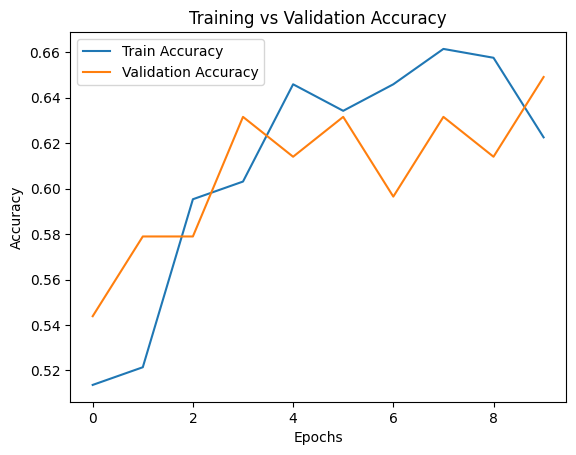

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training vs Validation Accuracy')
plt.show()

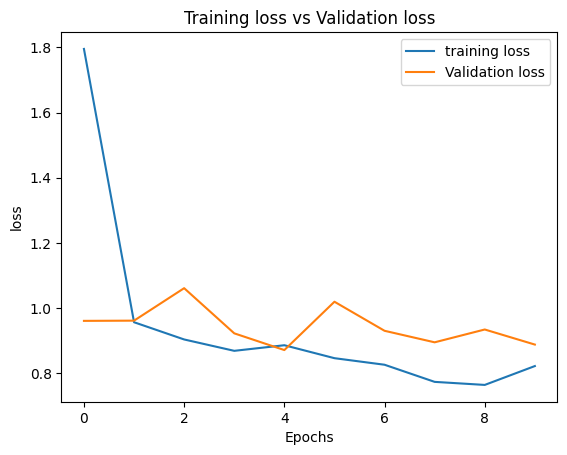

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='Validation loss')

plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.title('Training loss vs Validation loss')
plt.show()

In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

# 1. Load image
img_path = r"/content/download (5).jpg"
img = image.load_img(img_path, target_size=(224, 224))

# 2. Convert to array
img_array = image.img_to_array(img)

# 3. Normalize (same as training)
img_array = img_array / 255.0

# 4. Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# 5. Predict
prediction = model.predict(img_array)

# 6. Interpret result for multiclass
# Map indices back to the class names
class_labels = {v: k for k, v in train_data.class_indices.items()}
predicted_class_index = np.argmax(prediction[0])
predicted_class_name = class_labels[predicted_class_index]
confidence = prediction[0][predicted_class_index] * 100

print(f"Predicted Class: {predicted_class_name} ({confidence:.2f}% confidence)")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
Predicted Class: prabhas (47.79% confidence)
